# RMP trajectory analysis: opto-released NA (double-opto paradigm)

Companion to `rmp/rmp_plotting_by_genotypes_final.ipynb` (bath-applied NA:
`baseline`/`Noradrenaline`/`wash` as three separate dedicated files per cell),
adapted for the double-opto paradigm in
[`opto/ephys_double_opto.ipynb`](../opto/ephys_double_opto.ipynb), where NA is
released optogenetically and RGC stimulation drives real firing inside the
same sweeps the RMP is measured from.

## Design (v2 — revised after looking at the first validation figure)

The red test pulse at t=5.0s evokes a burst of spikes, so the original
`stimulus_windows` "Baseline" window (5.0-5.9s, borrowed from
`opto/ephys_double_opto.ipynb`'s firing-rate analysis, where sampling the
evoked response is exactly the point) is *not* a clean resting-potential
window — it measures the pulse response, not rest. **This notebook uses a
separate set of windows, `rmp_windows`, chosen to avoid every evoked
response:**

```
Baseline:     0.0 - 4.9s   (fully before the first pulse, in BOTH files)
Post-stim 1:  9.0 - 10.0s  (after the 8.1s pulse's response has settled, before the next)
Post-stim 2: 11.0 - 12.0s  (after the 10.1s pulse, before the next)
Post-stim 3: 13.0 - 14.0s  (after the 12.1s pulse, before the next)
Post-stim 4: 15.0 - 16.0s  (after the 14.1s pulse, before the next)
Post-stim 5: 17.0 - 18.0s  (after the 16.1s pulse)
```

Both `baseline` (dedicated baseline file) and `baseline_prelight` (the
Noradrenaline file's own pre-light period) now use the *same* `Baseline`
window and the *same* spike-excised extraction method — one consistent
methodology for every period, not first-100ms-of-sweep for one file and a
windowed method for the other. The two now agree much better than the first
pass (mean |diff| 2.75mV vs the >12mV outliers seen with the old 5.0-5.9s
window) — see the cross-check cell below.

**Per-sweep view**: each Noradrenaline/Control file has 5-20 repeated sweeps
spread ~40s apart (Noradrenaline/baseline files) or back-to-back (Control2).
This notebook computes RMP *per sweep*, not just the across-sweep average, so
a progressive drift from prolonged/repeated NA exposure is visible — see the
sweep-trend plots.

**Control group = WT mice** (`Control2` sheet of `double_opto_database_V4.xlsx`,
not the Dbh-cre `Control`/"Blue light" sheet used in the first pass of this
notebook). WT uses an older, structurally different single-pulse protocol
(blue light 2-7s, one red pulse at t=7s, response window 7-10s — verified
directly from a WT ABF file's epoch table and digital-output channel, not
just the protocol markdown note) — so it only has 2 timepoints
(`baseline`, `post_stim_1`), not 6. Its own `wt_control_windows` reflects
that, with Post-stim 1 at **7.9-8.9s** (0.9s after its one pulse, same
offset/width convention as the Noradrenaline windows — see the note below).

**Data source**: `/Users/rbondare/ephys/results/double_opto_database_V4.xlsx`
— the most complete version (19 Dbh-cre cells in `Noradrenaline`, 9 WT cells
in `Control2`). A dated snapshot is saved into this repo's `metadata/` folder.

**Fixed in the source spreadsheet** (with your confirmation): `filepath` for
Noradrenaline IDs 17-19 said `18.06.2026 M4` but those filenames live in
`18.06.2026 M5`; for Control (Dbh-cre sheet) IDs 4-6 it said `13.05.2026 M1`
instead of `13.05.2026 M2`. Both were genuine typos, now corrected directly
in `double_opto_database_V4.xlsx` (a backup of the pre-fix file was saved
alongside it as `double_opto_database_V4_backup_before_path_fix.xlsx`). All
19 Noradrenaline cells now resolve; only Control2 ID 9 drops out, because it
has no baseline row at all in the spreadsheet (not a path issue).

## Update: switched the primary comparison from absolute RMP to change-from-baseline (delta)

Comparing absolute RMP across timepoints (repeated-measures ANOVA +
Bonferroni post-hoc) came back "n.s." everywhere. Two problems with that:
(1) a bug — `pg.pairwise_tests(..., padjust='bonf')` was correcting across
all 15 possible pairs among the 6 timepoints before filtering down to the 5
"vs baseline" ones actually reported, a 3x-too-conservative correction; (2)
absolute RMP mixes in ~20mV of between-cell variability (baseline SD~5mV for
Noradrenaline) and the two groups even differ in baseline RMP from each
other (Welch t=2.91, p=0.0081) — a confound for comparing absolute values
between groups.

The question "does NA release change RMP" is a within-cell pre/post
question, so it belongs in **change from baseline (delta)**, which cancels
the between-cell offset. That reveals a real, NA-specific hyperpolarizing
shift: Noradrenaline cells hyperpolarize by **-3.18 +/- 4.72mV on average**
(pooled across post-stim 1-5, one-sample t p=0.011, Wilcoxon p=0.018,
Cohen's dz=0.67, 13/18 cells in that direction), individual post-stim
timepoints 2-4 remain significant even after a correctly-scoped Bonferroni
correction (bonf p=0.047, 0.036, 0.042), and Control shows no such shift
(+0.68 +/- 2.70mV, p=0.50). The between-group comparison at post-stim-1 (the
one timepoint both groups share) is significant: Welch t=-2.29, p=0.031,
Hedges g=-0.75.

`plot_double_opto_rmp_trajectory` (absolute RMP) and `compare_groups_per_timepoint`
have been replaced by the delta-based analysis below; `rmp_df` and
`rmp_sweep_df` themselves are unchanged (this was a stats/plotting fix, not
an extraction fix).

## Update: fixed an asymmetry in the WT Control window + added two more views

`wt_control_windows`' Post-stim 1 used to be **7.0-10.0s**, the original
firing-rate protocol's documented response-counting window — which starts
*at* the one WT pulse and so necessarily contains the evoked spike(s)
(visible in `spike_exclusion_validation_wt.png`: spikes land right inside
the shaded region, correctly excised before computing the mean, but still a
different *kind* of window than Noradrenaline's "quiet gap" Post-stim
points). It's now **7.9-8.9s** — 0.9s after the pulse, 1.0s wide, same
convention as `rmp_windows` — so the one timepoint the between-group test
relies on is comparable between groups. All numbers above were recomputed
with this fix (the previous WT Post-stim-1 values shift slightly).

Two more views were added after the delta trajectory plot: a **histogram of
per-cell pooled delta** (mirrors `plot_delta_rmp_per_sweep_histogram_single`
from `rmp_plotting_by_genotypes_final.ipynb`, showing distribution shape
rather than just mean±spread), and a **paired baseline-to-post-stim
connected-dot plot** (keeps the real mV values visible, which the delta plot
deliberately drops, while still showing each cell's individual shift).

In [1]:
import sys
from pathlib import Path

repo_root = Path.cwd().resolve().parent
sys.path.insert(0, str(repo_root))

import os
import re
import shutil
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyabf
import pingouin as pg
from scipy import stats
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multitest import multipletests

from ephys.ephys_functions import (
    detect_peaks,
    windowed_mean_excised,
    sweep_window_means_excised,
    extract_excised_per_sweep,
    extract_excised_trajectory_from_abf,
)

sns.set_context('poster')
sns.set_style('white')

In [2]:
LIVE_DB_PATH = '/Users/rbondare/ephys/results/double_opto_database_V4.xlsx'
SNAPSHOT_DIR = '/Users/rbondare/ephys-1/metadata'
RUN_SNAPSHOT = False  # set True only when you want to freeze a dated copy into this repo
DATA_SOURCE = LIVE_DB_PATH  # point this at a snapshot path once you've created one

# RMP-specific windows -- deliberately NOT the same as opto/ephys_double_opto.ipynb's
# stimulus_windows (those sample the evoked response on purpose; these avoid it).
# Pulse times for reference/plotting: baseline pulse 5.0s, then 8.1/10.1/12.1/14.1/16.1s.
PULSE_TIMES_DBH = [5.0, 8.1, 10.1, 12.1, 14.1, 16.1]
rmp_windows = [
    (0.0, 4.9, "Baseline", "#A2A0A0"),
    (9.0, 10.0, "Post-stim 1", "orange"),
    (11.0, 12.0, "Post-stim 2", "purple"),
    (13.0, 14.0, "Post-stim 3", "brown"),
    (15.0, 16.0, "Post-stim 4", "pink"),
    (17.0, 18.0, "Post-stim 5", "cyan"),
]

# WT (Control2) uses an older, different protocol -- verified directly from a WT ABF's
# epoch table + digital-output channel: blue light 2.0-7.0s, red pulse trigger at 7.0s.
# Post-stim 1 starts 0.9s after its pulse and is 1.0s wide, matching the offset/width
# convention rmp_windows uses for Noradrenaline (e.g. 9.0-10.0s is 0.9s after the 8.1s
# pulse) -- NOT 7.0-10.0s (the original firing-rate protocol's response-counting window),
# which starts AT the pulse and so necessarily includes the evoked spike(s) themselves.
# That window still gave a spike-excised, methodologically valid mean, but it measured a
# different kind of period than Noradrenaline's Post-stim 1 -- this keeps the one shared
# timepoint in the between-group test comparable.
PULSE_TIMES_WT = [7.0]
wt_control_windows = [
    (0.0, 1.9, "Baseline", "#A2A0A0"),
    (7.9, 8.9, "Post-stim 1", "orange"),
]

print('DATA_SOURCE:', DATA_SOURCE)
print('RUN_SNAPSHOT:', RUN_SNAPSHOT)

DATA_SOURCE: /Users/rbondare/ephys/results/double_opto_database_V4.xlsx
RUN_SNAPSHOT: False


In [3]:
def snapshot_double_opto_database(source_path, dest_dir, date_str=None):
    '''Whole-file copy (preserves the merged-header row and all sheets) into
    dest_dir with a dated filename. Skips with a message if today's snapshot
    already exists.'''
    date_str = date_str or date.today().isoformat()
    dest_name = f"double_opto_database_V4_{date_str}.xlsx"
    dest_path = os.path.join(dest_dir, dest_name)
    if os.path.exists(dest_path):
        print(f"Snapshot already exists, skipping: {dest_path}")
        return dest_path
    shutil.copy2(source_path, dest_path)
    print(f"Snapshot saved: {dest_path}")
    return dest_path


if RUN_SNAPSHOT:
    DATA_SOURCE = snapshot_double_opto_database(LIVE_DB_PATH, SNAPSHOT_DIR)
else:
    print('Skipping snapshot step.')

Skipping snapshot step.


## Load and clean the V4 database

Each row is one ABF file. `filepath` (folder) and `filename` can carry stray
whitespace/newlines — stripped before joining. `condition` values and header
row differ by sheet (`Noradrenaline`: `"Noradrenaline"`, merged title ->
`header=1`; `Control2`: `"Blue light"`, plain header -> `header=0`), so both
are parameters, not hardcoded. Rows commented `Exclude` are dropped; where an
ID has multiple valid rows for the same condition, the chronologically last
file is kept by sorting on the numeric filename suffix, not row order.

In [4]:
def clean_v4_sheet(xlsx_path, sheet_name, header=1):
    df = pd.read_excel(xlsx_path, sheet_name=sheet_name, header=header)
    df.columns = df.columns.astype(str).str.strip()
    df['filepath'] = df['filepath'].astype(str).str.strip()
    df['filename'] = df['filename'].astype(str).str.strip()
    df['full_path'] = df.apply(lambda r: os.path.join(r['filepath'], r['filename']), axis=1)
    df['condition_clean'] = df['condition'].astype(str).str.strip()
    df['is_excluded'] = df['comment'].astype(str).str.contains('exclude', case=False, na=False)

    def parse_suffix(fname):
        m = re.search(r'(\d+)\.abf$', fname, flags=re.IGNORECASE)
        return int(m.group(1)) if m else -1

    df['numeric_suffix'] = df['filename'].apply(parse_suffix)
    return df


def select_last_valid_file(df, condition_value, id_col='ID'):
    valid = df[(~df['is_excluded']) & (df['condition_clean'] == condition_value)].copy()
    if valid.empty:
        return valid
    valid = valid.sort_values('numeric_suffix')
    return valid.groupby(id_col, as_index=False).tail(1)


def build_cell_file_table(xlsx_path, sheet_name, stim_condition_value, group_label, header=1, id_col='ID'):
    raw = clean_v4_sheet(xlsx_path, sheet_name, header=header)
    all_ids = set(raw[id_col].dropna().unique())

    baseline_sel = select_last_valid_file(raw, 'baseline', id_col)
    stim_sel = select_last_valid_file(raw, stim_condition_value, id_col)

    baseline_sel = baseline_sel[[id_col, 'genotype', 'full_path', 'total_sweeps']].rename(
        columns={'full_path': 'baseline_filepath', 'total_sweeps': 'baseline_total_sweeps'})
    stim_sel = stim_sel[[id_col, 'full_path', 'total_sweeps', 'comment']].rename(
        columns={'full_path': 'stim_filepath', 'total_sweeps': 'stim_total_sweeps', 'comment': 'stim_comment'})

    # Inner join: an ID missing either side is automatically excluded
    merged = pd.merge(baseline_sel, stim_sel, on=id_col, how='inner')
    merged['group'] = group_label
    merged['subject_id'] = merged[id_col].apply(lambda x: f"{group_label}_{x}")

    # Diagnostics computed against the UNFILTERED id set, so an ID whose every
    # row got excluded is still reported, not silently absent.
    kept_ids = set(merged[id_col].unique())
    dropped_ids = all_ids - kept_ids
    dropped_rows = []
    for did in dropped_ids:
        has_baseline = did in set(baseline_sel[id_col])
        has_stim = did in set(stim_sel[id_col])
        reason = []
        if not has_baseline:
            reason.append('no valid baseline row')
        if not has_stim:
            reason.append(f'no valid {stim_condition_value} row')
        dropped_rows.append({'ID': did, 'reason': '; '.join(reason)})
    dropped_df = pd.DataFrame(dropped_rows)

    print(f"{group_label}: {len(all_ids)} raw IDs -> {len(merged)} usable cells ({len(dropped_ids)} dropped)")
    if len(dropped_df):
        print(dropped_df.to_string(index=False))
    return merged, dropped_df


na_table, na_dropped = build_cell_file_table(DATA_SOURCE, 'Noradrenaline', 'Noradrenaline', 'Noradrenaline', header=1)
ctrl_table, ctrl_dropped = build_cell_file_table(DATA_SOURCE, 'Control2', 'Blue light', 'Control', header=0)

Noradrenaline: 19 raw IDs -> 18 usable cells (1 dropped)
 ID                                            reason
  3 no valid baseline row; no valid Noradrenaline row
Control: 9 raw IDs -> 8 usable cells (1 dropped)
 ID                reason
  9 no valid baseline row


## Per-cell extraction (per-sweep and file-level, in one pass)

Both `baseline` (dedicated file) and `baseline_prelight`/`post_stim_1..5`
(Noradrenaline/Control2 file) now go through the *same* spike-excised,
windowed extraction (`extract_excised_per_sweep`) — one consistent method
everywhere. Each file is read once; the per-sweep detail and the file-level
average (`np.nanmean` across sweeps) are both derived from that single pass,
so nothing is extracted twice. Wrapped in try/except so a missing/unreadable
file is logged and skipped rather than stopping the run.

In [5]:
def window_label_to_col(label):
    if label == 'Baseline':
        return None
    return label.lower().replace('-', '_').replace(' ', '_')


def build_double_opto_rmp_tables(cell_file_table, windows, **excision_kwargs):
    '''Single pass per cell. Returns (summary_df, sweep_df, error_df):
    summary_df has one row per cell (baseline, baseline_prelight, post_stim_1..N);
    sweep_df is long-form (one row per cell x file_role x window x sweep).'''
    summary_rows, sweep_frames, errors = [], [], []
    window_labels = [w[2] for w in windows]

    for _, row in cell_file_table.iterrows():
        bf, sf = row['baseline_filepath'], row['stim_filepath']
        if not os.path.exists(bf) or not os.path.exists(sf):
            missing = bf if not os.path.exists(bf) else sf
            errors.append({'ID': row['ID'], 'group': row['group'], 'reason': f'file not found: {missing}'})
            continue
        try:
            baseline_per_sweep = extract_excised_per_sweep(bf, windows, **excision_kwargs)
            baseline_per_sweep = baseline_per_sweep[baseline_per_sweep['window'] == 'Baseline'].copy()
            baseline_per_sweep['file_role'] = 'baseline_file'

            stim_per_sweep = extract_excised_per_sweep(sf, windows, **excision_kwargs)
            stim_per_sweep['file_role'] = 'stim_file'
        except Exception as e:
            errors.append({'ID': row['ID'], 'group': row['group'], 'reason': str(e)})
            continue

        combined = pd.concat([baseline_per_sweep, stim_per_sweep], ignore_index=True)
        combined['ID'] = row['ID']
        combined['subject_id'] = row['subject_id']
        combined['group'] = row['group']
        sweep_frames.append(combined)

        def agg_mean(df_role, label):
            vals = df_role.loc[df_role['window'] == label, 'mean'].values
            return np.nan if len(vals) == 0 or np.all(np.isnan(vals)) else float(np.nanmean(vals))

        out = {
            'ID': row['ID'], 'subject_id': row['subject_id'], 'genotype': row['genotype'], 'group': row['group'],
            'baseline': agg_mean(baseline_per_sweep, 'Baseline'),
            'baseline_prelight': agg_mean(stim_per_sweep, 'Baseline'),
        }
        for label in window_labels:
            col = window_label_to_col(label)
            if col is None:
                continue
            out[col] = agg_mean(stim_per_sweep, label)
        out['n_sweeps_baseline'] = row['baseline_total_sweeps']
        out['n_sweeps_stim'] = row['stim_total_sweeps']
        out['baseline_filepath'] = bf
        out['stim_filepath'] = sf
        summary_rows.append(out)

    summary_df = pd.DataFrame(summary_rows)
    error_df = pd.DataFrame(errors)
    sweep_df = pd.concat(sweep_frames, ignore_index=True) if sweep_frames else pd.DataFrame()

    group_name = cell_file_table['group'].iloc[0] if len(cell_file_table) else '?'
    print(f"{group_name}: {len(summary_df)}/{len(cell_file_table)} cells processed successfully ({len(error_df)} failed)")
    if len(error_df):
        print(error_df.to_string(index=False))
    return summary_df, sweep_df, error_df


na_rmp, na_sweep_df, na_errors = build_double_opto_rmp_tables(na_table, rmp_windows)
ctrl_rmp, ctrl_sweep_df, ctrl_errors = build_double_opto_rmp_tables(ctrl_table, wt_control_windows)

rmp_df = pd.concat([na_rmp, ctrl_rmp], ignore_index=True)
rmp_sweep_df = pd.concat([na_sweep_df, ctrl_sweep_df], ignore_index=True)
print()
print('Final rmp_df shape:', rmp_df.shape, '| rmp_sweep_df shape:', rmp_sweep_df.shape)
rmp_df.head(10)

Noradrenaline: 18/18 cells processed successfully (0 failed)


Control: 8/8 cells processed successfully (0 failed)

Final rmp_df shape: (26, 15) | rmp_sweep_df shape: (1595, 9)


,ID,subject_id,genotype,group,baseline,baseline_prelight,post_stim_1,post_stim_2,post_stim_3,post_stim_4,post_stim_5,n_sweeps_baseline,n_sweeps_stim,baseline_filepath,stim_filepath
0,14,Noradrenaline_14,Dbh-cre,Noradrenaline,-63.253848,-61.741335,-64.072442,-64.138754,-63.427476,-62.908276,-62.333392,6,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
1,9,Noradrenaline_9,Dbh-cre,Noradrenaline,-55.869574,-58.090101,-64.539305,-63.595908,-63.546346,-62.744008,-62.310387,5,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
2,6,Noradrenaline_6,Dbh-cre,Noradrenaline,-62.173564,-62.488411,-69.193414,-68.098237,-66.280172,-65.528973,-65.055492,5,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
3,1,Noradrenaline_1,Dbh-cre,Noradrenaline,-67.384274,-64.923876,-64.396788,-64.775940,-65.193709,-65.481973,-65.732680,5,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
4,15,Noradrenaline_15,Dbh-cre,Noradrenaline,-55.844735,-60.650949,-61.941401,-61.239523,-61.516566,-61.073845,-61.355718,7,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
5,10,Noradrenaline_10,Dbh-cre,Noradrenaline,-62.226665,-60.484294,-60.461470,-61.484051,-61.577481,-61.478854,-61.732381,6,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
6,7,Noradrenaline_7,Dbh-cre,Noradrenaline,-60.843609,-61.114033,-65.257213,-65.604039,-64.822317,-64.734270,-64.795678,5,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
7,11,Noradrenaline_11,Dbh-cre,Noradrenaline,-63.895733,-68.258573,-71.787244,-72.096733,-71.858417,-71.788170,-71.471749,5,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
8,16,Noradrenaline_16,Dbh-cre,Noradrenaline,-52.165108,-58.664880,-65.215297,-63.109960,-59.340785,-58.348242,-59.764685,5,10,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...
9,8,Noradrenaline_8,Dbh-cre,Noradrenaline,-54.327271,-68.074534,-68.416201,-68.849752,-68.776370,-69.330205,-69.035970,5,3,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...,/Volumes/joeschgrp/Group Members/Rima/Ephys_NE...


## `baseline` vs `baseline_prelight` cross-check

Different files for the same cell (dedicated baseline file vs. the
Noradrenaline/Control2 file's own pre-light period), but now extracted with
the *same* window + method, so they should agree closely. They do, much
better than the first pass (mean |diff| ~2.75mV here vs. outliers over 12mV
with the old 5.0-5.9s window) — remaining differences reflect genuine
cell/recording variability between two separate recordings, not a
window-choice artifact.

In [6]:
rmp_df['baseline_diff'] = (rmp_df['baseline'] - rmp_df['baseline_prelight']).abs()
print(f"Mean |baseline - baseline_prelight|: {rmp_df['baseline_diff'].mean():.2f} mV")
flagged = rmp_df[rmp_df['baseline_diff'] > 5].sort_values('baseline_diff', ascending=False)
print(f"Cells with diff > 5 mV: {len(flagged)} / {len(rmp_df)}")
flagged[['ID', 'group', 'baseline', 'baseline_prelight', 'baseline_diff']]

Mean |baseline - baseline_prelight|: 2.75 mV
Cells with diff > 5 mV: 3 / 26


,ID,group,baseline,baseline_prelight,baseline_diff
9,8,Noradrenaline,-54.327271,-68.074534,13.747264
8,16,Noradrenaline,-52.165108,-58.664880,6.499771
16,19,Noradrenaline,-59.942459,-65.108902,5.166443


## Stats + plotting helpers

In [7]:
def add_significance(ax, pairs, pvalues, y_offset_from_top=-0.06, h=0.03, fontsize=12):
    '''Copied verbatim from rmp/rmp_plotting_by_genotypes_final.ipynb.'''
    ymin, ymax = ax.get_ylim()
    plot_height = ymax - ymin
    for i, ((x1, x2), pval) in enumerate(zip(pairs, pvalues)):
        if pval < 0.001:
            stars = '***'
        elif pval < 0.01:
            stars = '**'
        elif pval < 0.05:
            stars = '*'
        else:
            stars = 'n.s.'
        y = ymax - (y_offset_from_top + i * h) * plot_height
        bar_h = h * plot_height * 0.5
        ax.plot([x1, x1, x2, x2], [y, y - bar_h, y - bar_h, y], lw=1.5, c='k')
        ax.text((x1 + x2) / 2, y - bar_h * 0.5, stars, ha='center', va='top', fontsize=fontsize)

In [8]:
def build_delta_df(rmp_df, post_stim_cols=('post_stim_1', 'post_stim_2', 'post_stim_3', 'post_stim_4', 'post_stim_5')):
    '''Change from baseline per cell: delta_post_stim_N = post_stim_N - baseline.
    Cancels each cell's own baseline offset, which absolute-value comparisons don't.'''
    delta_df = rmp_df[['ID', 'subject_id', 'group']].copy()
    for col in post_stim_cols:
        if col in rmp_df.columns:
            delta_df[f'delta_{col}'] = rmp_df[col] - rmp_df['baseline']
    return delta_df


def test_delta_vs_zero(delta_values):
    '''One-sample t-test + Wilcoxon signed-rank of delta against 0, plus Cohen's dz
    and a simple hyperpolarize/depolarize count (sign test complement).'''
    vals = np.asarray(delta_values, dtype=float)
    vals = vals[~np.isnan(vals)]
    n = len(vals)
    if n < 2:
        return {'n': n, 'mean': np.nan, 'sd': np.nan, 't_p': np.nan, 'wilcoxon_p': np.nan,
                'dz': np.nan, 'n_neg': np.nan, 'n_pos': np.nan}
    _, t_p = stats.ttest_1samp(vals, 0)
    try:
        _, w_p = stats.wilcoxon(vals)
    except ValueError:
        w_p = np.nan
    return {
        'n': n, 'mean': vals.mean(), 'sd': vals.std(ddof=1),
        't_p': t_p, 'wilcoxon_p': w_p, 'dz': vals.mean() / vals.std(ddof=1),
        'n_neg': int((vals < 0).sum()), 'n_pos': int((vals > 0).sum()),
    }


def hedges_g(a, b):
    '''Bias-corrected standardized mean difference for two independent samples.'''
    a = np.asarray(a, dtype=float); a = a[~np.isnan(a)]
    b = np.asarray(b, dtype=float); b = b[~np.isnan(b)]
    na, nb = len(a), len(b)
    pooled_sd = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    d = (a.mean() - b.mean()) / pooled_sd
    correction = 1 - (3 / (4 * (na + nb) - 9))
    return d * correction


def run_within_group_delta_tests(delta_df, group, delta_cols):
    '''One-sample tests per timepoint for one group, Bonferroni-corrected ONLY
    across that group's own timepoint count (NOT pingouin's within-factor pairwise
    machinery, which by default corrects across all pairwise comparisons among every
    timepoint -- that over-correction is what masked the signal in the first pass).'''
    sub = delta_df[delta_df['group'] == group]
    results = {}
    raw_t, raw_w, valid_cols = [], [], []
    for col in delta_cols:
        if col not in sub.columns or sub[col].notna().sum() < 2:
            continue
        res = test_delta_vs_zero(sub[col].values)
        results[col] = res
        raw_t.append(res['t_p'])
        raw_w.append(res['wilcoxon_p'])
        valid_cols.append(col)
    if raw_t:
        _, t_corr, _, _ = multipletests(raw_t, method='bonferroni')
        _, w_corr, _, _ = multipletests(raw_w, method='bonferroni')
        for col, tc, wc in zip(valid_cols, t_corr, w_corr):
            results[col]['t_p_bonf'] = tc
            results[col]['wilcoxon_p_bonf'] = wc
    return results


def print_delta_test_table(group, tests):
    print(f"--- {group}: within-group delta vs 0 (Bonferroni across {len(tests)} timepoint(s)) ---")
    for col, r in tests.items():
        print(f"  {col}: n={r['n']}, mean={r['mean']:+.2f}, SD={r['sd']:.2f}, dz={r['dz']:.2f}, "
              f"t_p={r['t_p']:.4f} (bonf={r['t_p_bonf']:.4f}), "
              f"wilcoxon_p={r['wilcoxon_p']:.4f} (bonf={r['wilcoxon_p_bonf']:.4f}), "
              f"n_hyperpolarize={r['n_neg']}, n_depolarize={r['n_pos']}")


delta_df = build_delta_df(rmp_df)

na_delta_tests = run_within_group_delta_tests(delta_df, 'Noradrenaline',
    ['delta_post_stim_1', 'delta_post_stim_2', 'delta_post_stim_3', 'delta_post_stim_4', 'delta_post_stim_5'])
print_delta_test_table('Noradrenaline', na_delta_tests)
print()
ctrl_delta_tests = run_within_group_delta_tests(delta_df, 'Control', ['delta_post_stim_1'])
print_delta_test_table('Control', ctrl_delta_tests)
print()

# Pooled delta: mean of post_stim_1-5 per NA cell -- a single higher-power confirmatory test
na_sub = delta_df[delta_df['group'] == 'Noradrenaline']
pooled_delta = na_sub[['delta_post_stim_1', 'delta_post_stim_2', 'delta_post_stim_3', 'delta_post_stim_4', 'delta_post_stim_5']].mean(axis=1)
pooled_res = test_delta_vs_zero(pooled_delta.values)
print(f"NA pooled delta (mean of post_stim_1-5 minus baseline): mean={pooled_res['mean']:+.2f} SD={pooled_res['sd']:.2f} mV, "
      f"t_p={pooled_res['t_p']:.4f}, wilcoxon_p={pooled_res['wilcoxon_p']:.4f}, dz={pooled_res['dz']:.2f}, "
      f"n_hyperpolarize={pooled_res['n_neg']}, n_depolarize={pooled_res['n_pos']}")
print()

# Between-group test at post-stim-1 -- the one timepoint both groups share, and the key
# "is this NA-specific" comparison (confound-free, unlike comparing absolute values).
na_d1 = delta_df.loc[delta_df['group'] == 'Noradrenaline', 'delta_post_stim_1'].dropna().values
ctrl_d1 = delta_df.loc[delta_df['group'] == 'Control', 'delta_post_stim_1'].dropna().values
t_stat, p_val = stats.ttest_ind(na_d1, ctrl_d1, equal_var=False)
g = hedges_g(na_d1, ctrl_d1)
print(f"Between-group (Noradrenaline vs Control) delta at post-stim-1: Welch t={t_stat:.2f}, p={p_val:.4f}, Hedges g={g:.2f}")
print(f"  Noradrenaline: n={len(na_d1)}, mean={na_d1.mean():+.2f} | Control: n={len(ctrl_d1)}, mean={ctrl_d1.mean():+.2f}")

--- Noradrenaline: within-group delta vs 0 (Bonferroni across 5 timepoint(s)) ---
  delta_post_stim_1: n=18, mean=-3.07, SD=5.64, dz=-0.54, t_p=0.0340 (bonf=0.1702), wilcoxon_p=0.0539 (bonf=0.2693), n_hyperpolarize=12, n_depolarize=6
  delta_post_stim_2: n=18, mean=-3.43, SD=4.99, dz=-0.69, t_p=0.0095 (bonf=0.0474), wilcoxon_p=0.0159 (bonf=0.0797), n_hyperpolarize=12, n_depolarize=6
  delta_post_stim_3: n=18, mean=-3.25, SD=4.51, dz=-0.72, t_p=0.0072 (bonf=0.0360), wilcoxon_p=0.0090 (bonf=0.0448), n_hyperpolarize=13, n_depolarize=5
  delta_post_stim_4: n=18, mean=-3.13, SD=4.46, dz=-0.70, t_p=0.0084 (bonf=0.0421), wilcoxon_p=0.0139 (bonf=0.0694), n_hyperpolarize=11, n_depolarize=7
  delta_post_stim_5: n=18, mean=-3.04, SD=4.48, dz=-0.68, t_p=0.0105 (bonf=0.0524), wilcoxon_p=0.0159 (bonf=0.0797), n_hyperpolarize=11, n_depolarize=7

--- Control: within-group delta vs 0 (Bonferroni across 1 timepoint(s)) ---
  delta_post_stim_1: n=8, mean=-0.32, SD=2.87, dz=-0.11, t_p=0.7592 (bonf=0.7592)

Saved /Users/rbondare/ephys-1/rmp/rmp_delta_trajectory.png


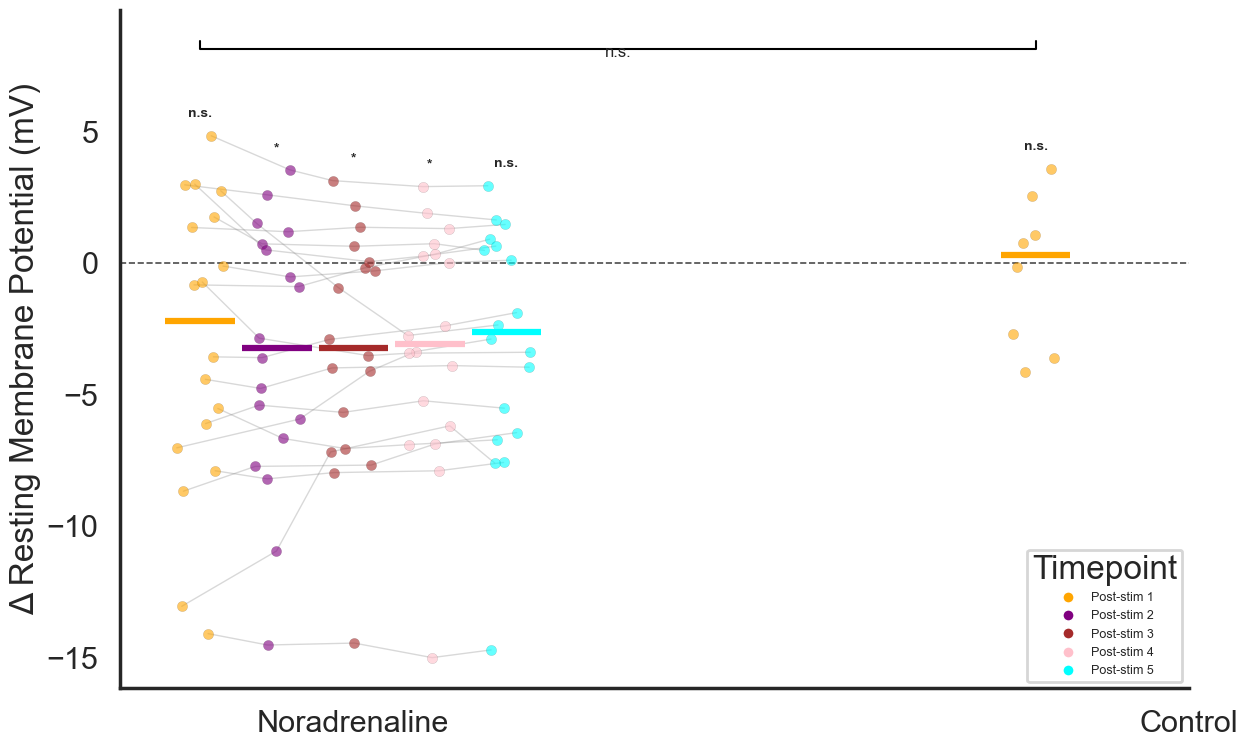

In [9]:
def plot_double_opto_rmp_delta_trajectory(
    delta_df,
    timepoints=('delta_post_stim_1', 'delta_post_stim_2', 'delta_post_stim_3', 'delta_post_stim_4', 'delta_post_stim_5'),
    timepoint_labels=('Post-stim 1', 'Post-stim 2', 'Post-stim 3', 'Post-stim 4', 'Post-stim 5'),
    group_order=('Noradrenaline', 'Control'),
    timepoint_colors=('orange', 'purple', 'brown', 'pink', 'cyan'),
    group_spacing=2.4, timepoint_width=0.22, jitter_amount=0.07,
    ylim=None, savepath=None,
):
    '''Primary inferential figure, replacing plot_double_opto_rmp_trajectory
    (absolute RMP). group is the outer facet; within-group significance stars (vs 0,
    Bonferroni-corrected across each group's own valid timepoints -- see
    run_within_group_delta_tests) sit above each column; the one between-group bracket
    compares Noradrenaline vs Control at post-stim-1, the only timepoint both have.'''
    groups = [g for g in group_order if g in delta_df['group'].unique()]
    group_within_tests, group_positions = {}, {}

    for group in groups:
        valid_cols = [tp for tp in timepoints
                      if tp in delta_df.columns and delta_df.loc[delta_df['group'] == group, tp].notna().any()]
        group_within_tests[group] = run_within_group_delta_tests(delta_df, group, valid_cols)

    plt.figure(figsize=(13, 8))
    ax = plt.gca()
    n_tp = len(timepoints)
    np.random.seed(42)

    for g_idx, group in enumerate(groups):
        sub = delta_df[delta_df['group'] == group]
        center = g_idx * group_spacing
        positions = [center + (i - (n_tp - 1) / 2) * timepoint_width for i in range(n_tp)]
        group_positions[group] = positions

        for _, row in sub.iterrows():
            y = [row[tp] if tp in row.index else np.nan for tp in timepoints]
            x_j = [positions[i] + np.random.uniform(-jitter_amount, jitter_amount) for i in range(n_tp)]
            valid = [i for i in range(n_tp) if pd.notna(y[i])]
            if len(valid) > 1:
                ax.plot([x_j[i] for i in valid], [y[i] for i in valid], color='gray', alpha=0.3, linewidth=1, zorder=1)
            for i in range(n_tp):
                if pd.notna(y[i]):
                    ax.scatter(x_j[i], y[i], color=timepoint_colors[i], alpha=0.6, s=55, zorder=2, edgecolors='black', linewidths=0.1)

        for i, tp in enumerate(timepoints):
            if tp not in sub.columns:
                continue
            yv = sub[tp].dropna().values
            if len(yv) > 0:
                ax.hlines(np.median(yv), positions[i] - 0.1, positions[i] + 0.1, color=timepoint_colors[i], linewidth=4.5, zorder=3)

    ax.axhline(0, color='black', linestyle='--', linewidth=1.2, alpha=0.7, zorder=0)

    # Within-group significance stars (vs 0), placed above each column's highest point
    for group in groups:
        tests = group_within_tests[group]
        positions = group_positions[group]
        sub = delta_df[delta_df['group'] == group]
        for i, tp in enumerate(timepoints):
            if tp not in tests:
                continue
            p_corr = tests[tp].get('t_p_bonf', np.nan)
            if np.isnan(p_corr):
                continue
            stars = '***' if p_corr < 0.001 else '**' if p_corr < 0.01 else '*' if p_corr < 0.05 else 'n.s.'
            col_vals = sub[tp].dropna().values
            y_top = col_vals.max() if len(col_vals) else 0
            ax.text(positions[i], y_top + 0.6, stars, ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Between-group bracket at the one shared timepoint (post-stim-1)
    shared_tp = timepoints[0]
    if len(groups) == 2 and all(
        shared_tp in delta_df.columns and delta_df.loc[delta_df['group'] == g, shared_tp].notna().any() for g in groups
    ):
        a = delta_df.loc[delta_df['group'] == groups[0], shared_tp].dropna().values
        b = delta_df.loc[delta_df['group'] == groups[1], shared_tp].dropna().values
        if len(a) >= 2 and len(b) >= 2:
            _, p_val = stats.ttest_ind(a, b, equal_var=False)
            x1, x2 = group_positions[groups[0]][0], group_positions[groups[1]][0]
            add_significance(ax, [(x1, x2)], [p_val], y_offset_from_top=-0.12)

    centers = [i * group_spacing for i in range(len(groups))]
    ax.set_xticks(centers)
    ax.set_xticklabels(groups)
    ax.set_ylabel('Δ Resting Membrane Potential (mV)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if ylim is not None:
        ax.set_ylim(ylim)

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=8, label=l)
                       for c, l in zip(timepoint_colors, timepoint_labels)]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=9, title='Timepoint')
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
        print('Saved', savepath)
    plt.show()
    return group_within_tests


delta_within_tests = plot_double_opto_rmp_delta_trajectory(
    delta_df, savepath='/Users/rbondare/ephys-1/rmp/rmp_delta_trajectory.png'
)

## Two more views of the same result

The delta trajectory above shows the change per timepoint but drops the
real mV values and doesn't show the shape of the response distribution.
These two complement it rather than replace it.

Saved /Users/rbondare/ephys-1/rmp/rmp_delta_histogram.png


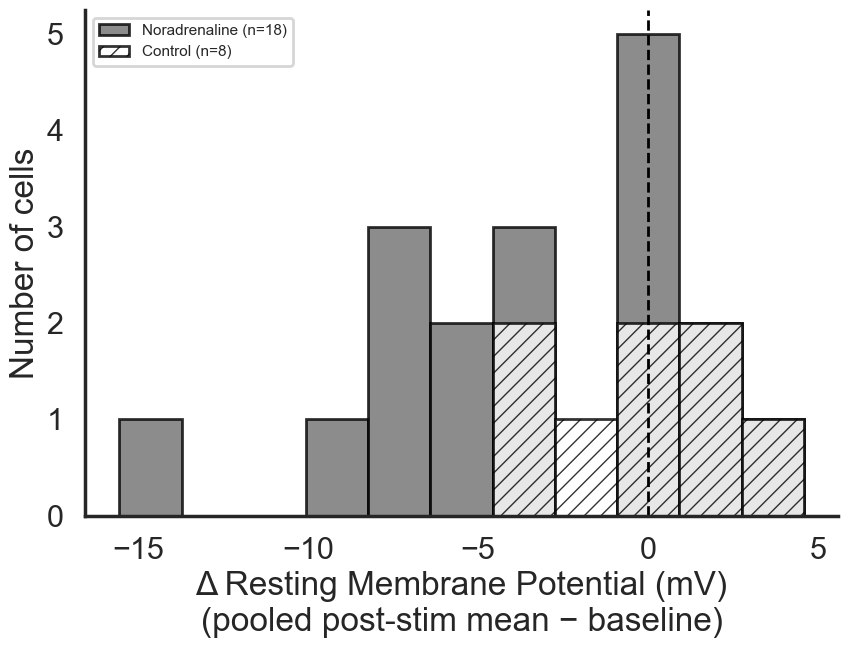

In [10]:
def plot_delta_histogram(delta_df, group_order=('Noradrenaline', 'Control'), bins=12, savepath=None):
    '''Histogram of per-cell pooled delta (mean of all post-stim timepoints minus
    baseline for Noradrenaline; post_stim_1 minus baseline for Control -- its only
    timepoint). Mirrors plot_delta_rmp_per_sweep_histogram_single from
    rmp_plotting_by_genotypes_final.ipynb, but one value per cell (not per sweep) to
    avoid pseudo-replication -- consistent with the unit of analysis used throughout
    this notebook's stats.'''
    post_stim_cols = [c for c in delta_df.columns if c.startswith('delta_post_stim_')]

    pooled_by_group = {}
    for group in group_order:
        if group not in delta_df['group'].unique():
            continue
        sub = delta_df[delta_df['group'] == group]
        valid_cols = [c for c in post_stim_cols if sub[c].notna().any()]
        pooled_by_group[group] = sub[valid_cols].mean(axis=1).dropna()

    all_vals = pd.concat(pooled_by_group.values())
    bin_edges = np.linspace(all_vals.min() - 1, all_vals.max() + 1, bins)

    colors = {'Noradrenaline': '#707070', 'Control': 'white'}
    hatches = {'Noradrenaline': None, 'Control': '//'}

    plt.figure(figsize=(9, 7))
    for group, vals in pooled_by_group.items():
        plt.hist(vals, bins=bin_edges, color=colors.get(group, 'gray'), edgecolor='black',
                  hatch=hatches.get(group), alpha=0.8, label=f'{group} (n={len(vals)})')

    plt.axvline(0, color='black', linestyle='--', linewidth=2)
    plt.xlabel('Δ Resting Membrane Potential (mV)\n(pooled post-stim mean − baseline)')
    plt.ylabel('Number of cells')
    plt.legend(fontsize=11)
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
        print('Saved', savepath)
    plt.show()


plot_delta_histogram(delta_df, savepath='/Users/rbondare/ephys-1/rmp/rmp_delta_histogram.png')

Saved /Users/rbondare/ephys-1/rmp/rmp_paired_before_after.png


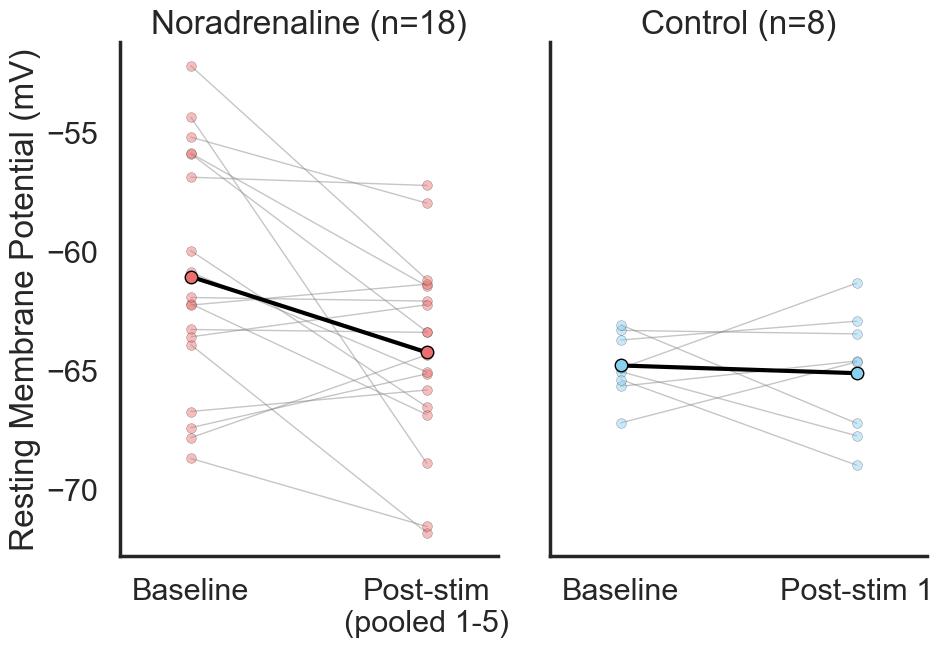

In [11]:
def plot_paired_before_after(rmp_df, savepath=None):
    '''Connected dot plot: baseline -> pooled post-stim mean (Noradrenaline) or
    post_stim_1 (Control), one line per cell, real mV values. Complements the delta
    plot/histogram by keeping absolute RMP visible alongside the paired shift.'''
    na_sub = rmp_df[rmp_df['group'] == 'Noradrenaline'].copy()
    post_cols = ['post_stim_1', 'post_stim_2', 'post_stim_3', 'post_stim_4', 'post_stim_5']
    na_sub['post_pooled'] = na_sub[post_cols].mean(axis=1)

    ctrl_sub = rmp_df[rmp_df['group'] == 'Control'].copy()
    ctrl_sub['post_pooled'] = ctrl_sub['post_stim_1']

    panels = [('Noradrenaline', na_sub, '#EB6F6F', 'Post-stim\n(pooled 1-5)'),
              ('Control', ctrl_sub, '#89CFF0', 'Post-stim 1')]

    fig, axes = plt.subplots(1, 2, figsize=(10, 7), sharey=True)
    for ax, (title, sub, color, post_label) in zip(axes, panels):
        for _, row in sub.iterrows():
            ax.plot([0, 1], [row['baseline'], row['post_pooled']], color='gray', alpha=0.45,
                     linewidth=1, marker='o', markersize=7, markerfacecolor=color,
                     markeredgecolor='black', markeredgewidth=0.3, zorder=2)

        mean_baseline = sub['baseline'].mean()
        mean_post = sub['post_pooled'].mean()
        ax.plot([0, 1], [mean_baseline, mean_post], color='black', linewidth=3, zorder=3,
                 marker='o', markersize=9, markerfacecolor=color, markeredgecolor='black')

        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Baseline', post_label])
        ax.set_title(f'{title} (n={len(sub)})')
        ax.set_xlim(-0.3, 1.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    axes[0].set_ylabel('Resting Membrane Potential (mV)')
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
        print('Saved', savepath)
    plt.show()


plot_paired_before_after(rmp_df, savepath='/Users/rbondare/ephys-1/rmp/rmp_paired_before_after.png')

## RMP per sweep (prolonged-NA-exposure check)

For each window, RMP across the repeated sweeps within one file (thin lines
= individual cells, thick line + band = mean ± SEM across cells). Noradrenaline
sweeps are ~40s apart (so sweep 10 is ~6 minutes of repeated blue-light
exposure after sweep 1); Control2 sweeps run back-to-back. A flat line means
no detectable cumulative effect of repeated/prolonged exposure; a slope means
there is one.

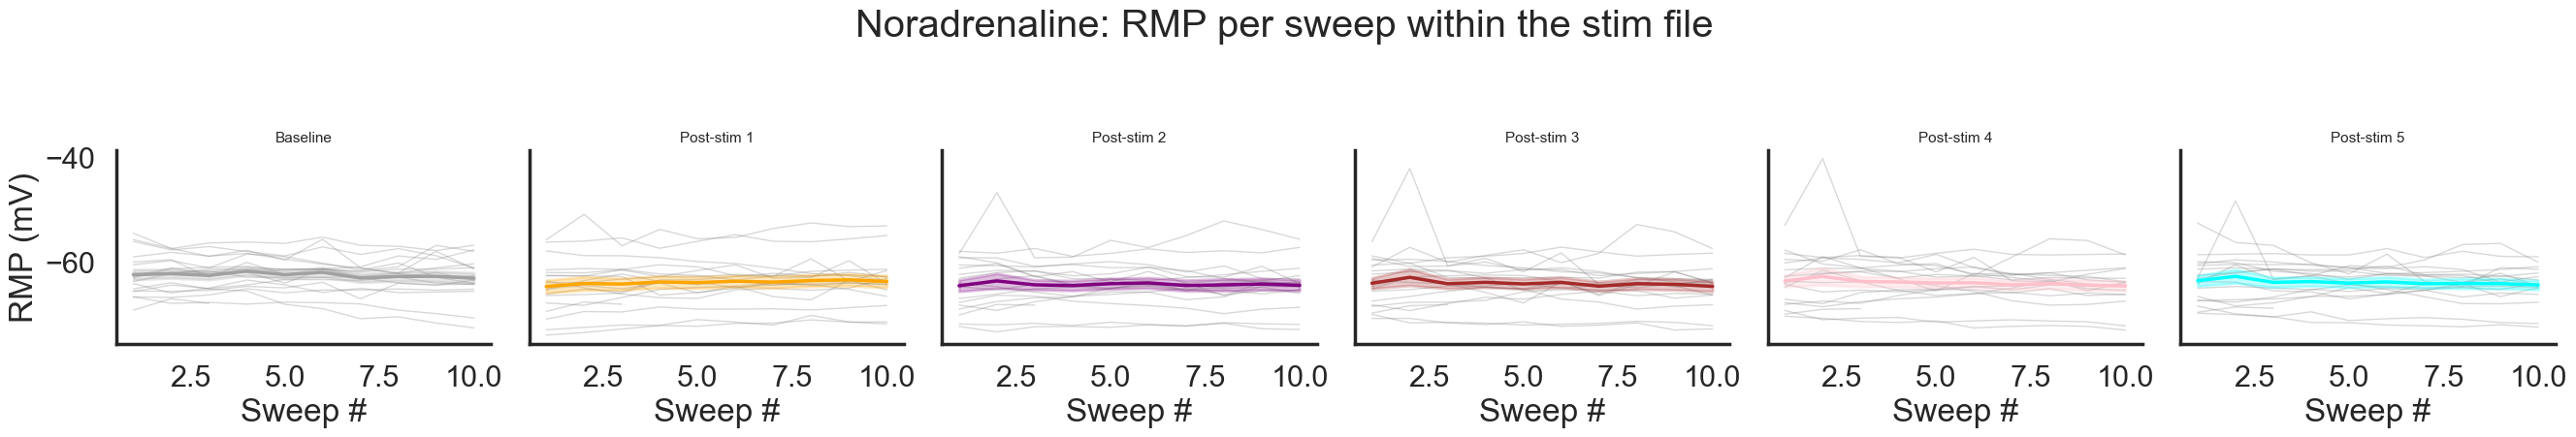

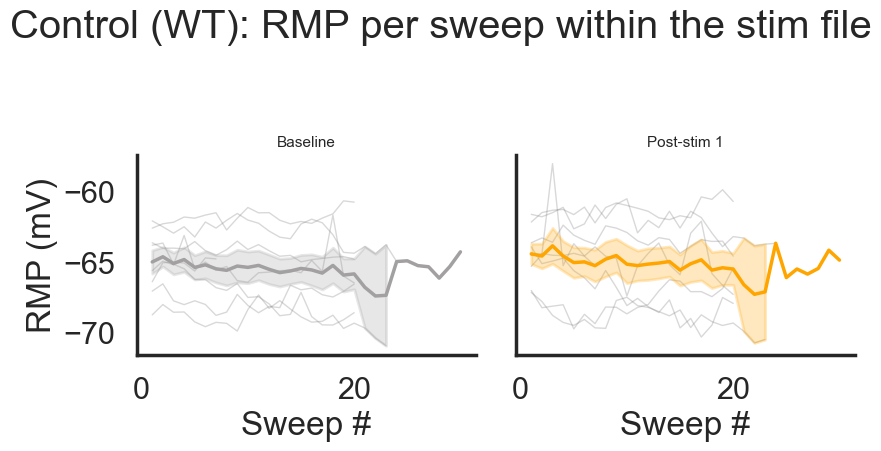

In [12]:
def plot_rmp_by_sweep(rmp_sweep_df, group, window_labels, window_colors, title=None, savepath=None):
    sub = rmp_sweep_df[
        (rmp_sweep_df['group'] == group)
        & (rmp_sweep_df['file_role'] == 'stim_file')
        & (rmp_sweep_df['window'].isin(window_labels))
    ]
    n_windows = len(window_labels)
    fig, axes = plt.subplots(1, n_windows, figsize=(4.5 * n_windows, 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, label, color in zip(axes, window_labels, window_colors):
        wdf = sub[sub['window'] == label]
        for cell_id, cell_df in wdf.groupby('ID'):
            cell_df = cell_df.sort_values('sweep')
            ax.plot(cell_df['sweep'] + 1, cell_df['mean'], color='gray', alpha=0.3, linewidth=1)

        stats_by_sweep = wdf.groupby('sweep')['mean'].agg(['mean', 'sem']).reset_index()
        ax.plot(stats_by_sweep['sweep'] + 1, stats_by_sweep['mean'], color=color, linewidth=2.5, zorder=3)
        ax.fill_between(stats_by_sweep['sweep'] + 1,
                         stats_by_sweep['mean'] - stats_by_sweep['sem'],
                         stats_by_sweep['mean'] + stats_by_sweep['sem'],
                         color=color, alpha=0.25, zorder=2)

        ax.set_title(label, fontsize=11)
        ax.set_xlabel('Sweep #')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    axes[0].set_ylabel('RMP (mV)')
    if title:
        fig.suptitle(title, y=1.04)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200, bbox_inches='tight')
        print('Saved', savepath)
    plt.show()


na_window_labels = [w[2] for w in rmp_windows]
na_window_colors = [w[3] for w in rmp_windows]
plot_rmp_by_sweep(rmp_sweep_df, 'Noradrenaline', na_window_labels, na_window_colors,
                   title='Noradrenaline: RMP per sweep within the stim file')

ctrl_window_labels = [w[2] for w in wt_control_windows]
ctrl_window_colors = [w[3] for w in wt_control_windows]
plot_rmp_by_sweep(rmp_sweep_df, 'Control', ctrl_window_labels, ctrl_window_colors,
                   title='Control (WT): RMP per sweep within the stim file')

## Spike-exclusion validation

Shows exactly which period produces each number: the shaded band is the RMP
window actually averaged (label + computed mean + excised-sample count
printed on it); the dashed vertical lines mark the red/blue stimulus pulse
times from the *original* `opto/ephys_double_opto.ipynb` protocol, shown only
for reference so it's visually obvious the RMP windows deliberately sit
*between* pulses rather than on top of the evoked response. Detected spikes
are marked, with the excised region around each one shaded in red.

Saved /Users/rbondare/ephys-1/rmp/spike_exclusion_validation.png


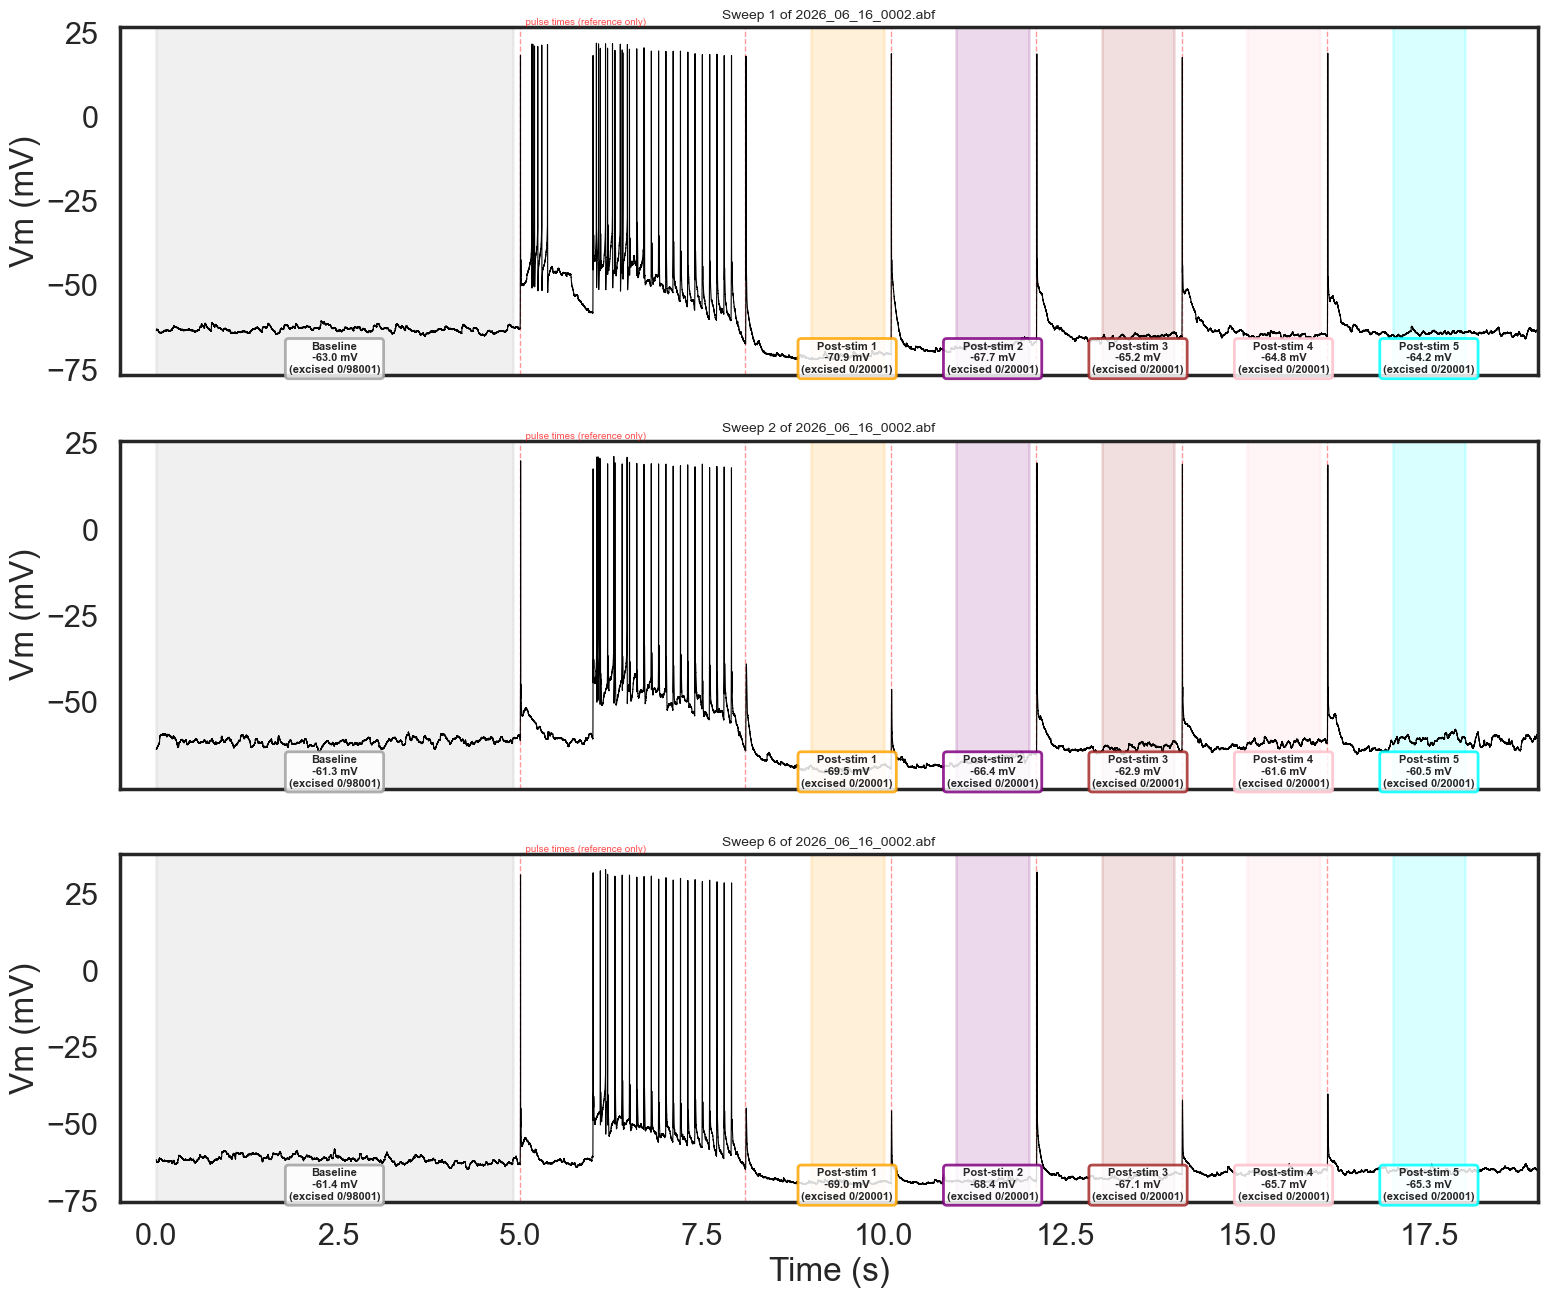

Saved /Users/rbondare/ephys-1/rmp/spike_exclusion_validation_wt.png


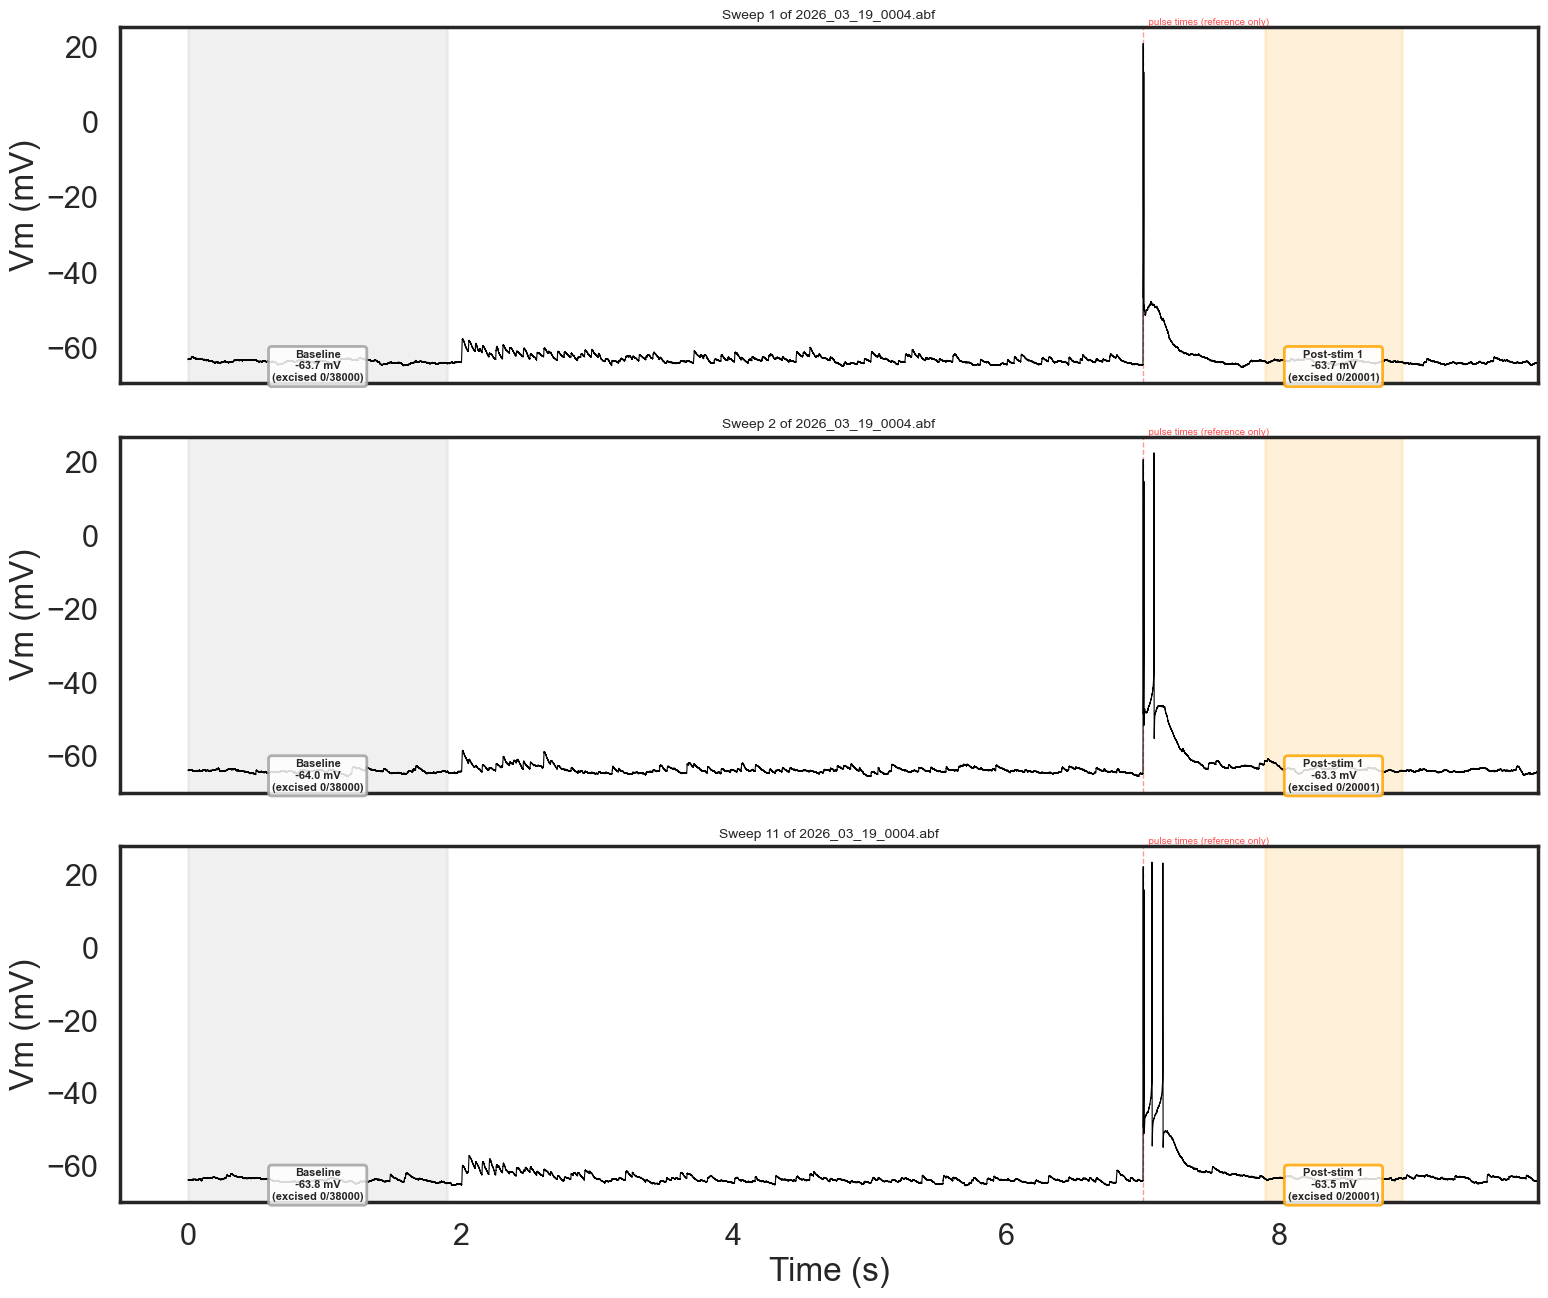

In [13]:
def plot_spike_exclusion_validation(abf_file, windows, pulse_times=None, sweep_indices=None,
                                     height_threshold=4, prominence_min=0.1, distance_min=5,
                                     exclude_pre_ms=5.0, exclude_post_ms=15.0,
                                     savepath='/Users/rbondare/ephys-1/rmp/spike_exclusion_validation.png'):
    abf = pyabf.ABF(abf_file)
    all_sweeps = abf.sweepList

    if sweep_indices is None:
        peak_counts = []
        for sweep in all_sweeps:
            abf.setSweep(sweep)
            results = sweep_window_means_excised(abf.sweepX, abf.sweepY, windows, abf.dataRate,
                                                  height_threshold=height_threshold, prominence_min=prominence_min,
                                                  distance_min=distance_min, exclude_pre_ms=exclude_pre_ms, exclude_post_ms=exclude_post_ms)
            total_peaks = sum(len(r['peak_indices_global']) for r in results.values())
            peak_counts.append((sweep, total_peaks))
        peak_counts.sort(key=lambda x: -x[1])
        top_firing = [s for s, c in peak_counts[:2] if c > 0]
        sweep_indices = [all_sweeps[0]] + top_firing
        if len(sweep_indices) < 3:
            # the RMP windows deliberately avoid the evoked response, so it's common
            # for NO sweep to have in-window spikes -- pad with spread-out sweeps for
            # broader coverage rather than showing a single (likely all-clean) panel
            remaining = [s for s in all_sweeps if s not in sweep_indices]
            n_needed = 3 - len(sweep_indices)
            if remaining:
                step = max(1, len(remaining) // n_needed)
                sweep_indices += remaining[::step][:n_needed]
        sweep_indices = list(dict.fromkeys(sweep_indices))

    n_rows = len(sweep_indices)
    fig, axes = plt.subplots(n_rows, 1, figsize=(16, 4.5 * n_rows), sharex=True)
    axes = np.atleast_1d(axes)

    x_start = min(0.0, windows[0][0]) - 0.5
    x_end = windows[-1][1] + 1.0

    for ax, sweep in zip(axes, sweep_indices):
        abf.setSweep(sweep)
        x, y = abf.sweepX, abf.sweepY
        ax.plot(x, y, color='black', linewidth=0.8, zorder=1)

        results = sweep_window_means_excised(x, y, windows, abf.dataRate,
                                              height_threshold=height_threshold, prominence_min=prominence_min,
                                              distance_min=distance_min, exclude_pre_ms=exclude_pre_ms, exclude_post_ms=exclude_post_ms)

        if pulse_times:
            for pt in pulse_times:
                ax.axvline(pt, color='red', linestyle='--', alpha=0.4, linewidth=1, zorder=0)
            ax.text(pulse_times[0], ax.get_ylim()[1], '  pulse times (reference only)',
                    fontsize=7, color='red', alpha=0.7, va='bottom')

        for start, end, label, color in windows:
            ax.axvspan(start, end, color=color, alpha=0.15, zorder=0)
            r = results[label]
            if len(r['peak_indices_global']) > 0:
                ax.scatter(x[r['peak_indices_global']], y[r['peak_indices_global']], color=color, s=40, zorder=3, edgecolors='black', linewidths=0.3)
                for p in r['peak_indices_global']:
                    peak_t = x[p]
                    ax.axvspan(peak_t - exclude_pre_ms / 1000, peak_t + exclude_post_ms / 1000, color='red', alpha=0.3, zorder=1)
            mean_str = f"{r['mean']:.1f} mV" if not np.isnan(r['mean']) else "NaN"
            ax.text((start + end) / 2, ax.get_ylim()[0], f"{label}\n{mean_str}\n(excised {r['n_excised']}/{r['n_total']})",
                    ha='center', va='bottom', fontsize=8, fontweight='bold',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor=color))

        ax.set_title(f"Sweep {sweep + 1} of {os.path.basename(abf_file)}", fontsize=10)
        ax.set_ylabel("Vm (mV)")
        ax.set_xlim(x_start, x_end)

    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
        print('Saved', savepath)
    plt.show()


demo_file_dbh = os.path.join(
    "/Volumes/joeschgrp/Group Members/Rima/Ephys_NE/DATA/double_opto/20.04.2026",
    "16.06.2026 M1/2026_06_16_0002.abf",
)
if os.path.exists(demo_file_dbh):
    plot_spike_exclusion_validation(demo_file_dbh, rmp_windows, pulse_times=PULSE_TIMES_DBH,
                                     savepath='/Users/rbondare/ephys-1/rmp/spike_exclusion_validation.png')
else:
    print(f"Demo file not found (network drive not mounted?): {demo_file_dbh}")

demo_file_wt = os.path.join(
    "/Volumes/joeschgrp/Group Members/Rima/Ephys_NE/DATA/double_opto/19.03.2026_control",
    "19.03.2026 M2/2026_03_19_0004.abf",
)
if os.path.exists(demo_file_wt):
    plot_spike_exclusion_validation(demo_file_wt, wt_control_windows, pulse_times=PULSE_TIMES_WT,
                                     savepath='/Users/rbondare/ephys-1/rmp/spike_exclusion_validation_wt.png')
else:
    print(f"WT demo file not found (network drive not mounted?): {demo_file_wt}")